## Regression Assumptions and Diagnostics

### Learning Goals
* Understand why residual diagnostics are essential for verifying OLS regression assumptions.
* Recognize the impacts of heteroskedasticity, non-linearity, and serial correlation.
* Implement robust standard errors (HC3) in Python using `statsmodels` to account for heteroskedasticity.

---

### 1. Why Diagnose a Regression?

A fitted line alone cannot verify whether a model satisfies its underlying statistical assumptions. Important diagnostic considerations include:
* **Non-linearity:** Systematic curvature in residuals versus fitted values.
* **Heteroskedasticity:** Non-constant error variance across observations.
* **Correlated Errors:** Serial correlation or clustering in error terms.
* **Influential Observations:** Outliers that disproportionately skew coefficient estimates.
* **Omitted Variables & Endogeneity:** Violations of exogeneity ($\mathbb{E}[\epsilon \mid X] \neq 0$).

> **Core Implication:** Heteroskedasticity renders conventional OLS standard errors unreliable (invalidating hypothesis tests and confidence intervals), even though coefficient estimates remain unbiased under valid exogeneity.

<>:19: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:19: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
/tmp/ipykernel_4724/2855361485.py:19: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  plt.xlabel("Fitted Values ($\hat{y}$)")


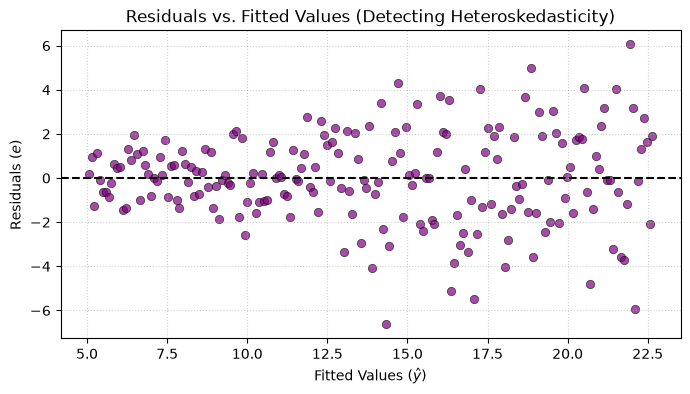

Conventional Standard Errors:
[0.34029329 0.05589266]

HC3 Robust Standard Errors:
[0.24485596 0.05540204]


In [1]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

rng = np.random.default_rng(21)
x = np.linspace(1, 10, 200)

# Introduce heteroskedastic noise (variance increases with x)
noise_scale = 0.3 + 0.35 * x
y = 3 + 2 * x + rng.normal(0, noise_scale)

result = sm.OLS(y, sm.add_constant(x)).fit()
fitted = result.fittedvalues
residuals = result.resid

plt.figure(figsize=(8, 4))
plt.scatter(fitted, residuals, color='purple', alpha=0.7, edgecolor='k', linewidth=0.5)
plt.axhline(0, color='black', linestyle="--", linewidth=1.5)
plt.xlabel("Fitted Values ($\hat{y}$)")
plt.ylabel("Residuals ($e$)")
plt.title("Residuals vs. Fitted Values (Detecting Heteroskedasticity)")
plt.grid(linestyle=':', alpha=0.6)
plt.show()

# Compute robust HC3 standard errors
robust_result = result.get_robustcov_results(cov_type="HC3")

print("Conventional Standard Errors:")
print(result.bse)
print("\nHC3 Robust Standard Errors:")
print(robust_result.bse)

---

### Exercises

Try each problem before running the verification code below:

1. Describe the visual pattern observed in the residual plot above (fan-shape / megaphone pattern).
2. Explain what **heteroskedasticity** means in the context of economic data.
3. Why do robust standard errors *not* fix omitted-variable bias?

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print("\n1. Residual Plot Pattern:")
print("   - The dispersion of residuals widens as fitted values increase (funnel or megaphone shape),")
print("     indicating that error variance is not constant.")

print("\n2. Definition of Heteroskedasticity:")
print("   - Heteroskedasticity occurs when the variance of the error term ($\epsilon$) is not")
print("     constant across observations of the explanatory variables.")

print("\n3. Robust Standard Errors vs. Omitted-Variable Bias:")
print("   - Robust standard errors correct the standard deviation of coefficient estimates for")
print("     unequal variance, but they cannot restore exogeneity when a key confounder is omitted.")

=== Exercise Solutions & Checks ===

1. Residual Plot Pattern:
   - The dispersion of residuals widens as fitted values increase (funnel or megaphone shape),
     indicating that error variance is not constant.

2. Definition of Heteroskedasticity:
   - Heteroskedasticity occurs when the variance of the error term ($\epsilon$) is not
     constant across observations of the explanatory variables.

3. Robust Standard Errors vs. Omitted-Variable Bias:
   - Robust standard errors correct the standard deviation of coefficient estimates for
     unequal variance, but they cannot restore exogeneity when a key confounder is omitted.


<>:9: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:9: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
/tmp/ipykernel_4724/209396006.py:9: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  print("   - Heteroskedasticity occurs when the variance of the error term ($\epsilon$) is not")
